# Proyecto Final - Predicción de Customer Churn


## Contexto del problema

Las empresas de telecomunicaciones enfrentan un desafío constante relacionado con la pérdida de clientes (Customer Churn). Cada cliente que abandona la empresa representa una disminución de ingresos y un costo adicional para captar nuevos clientes.

El objetivo de este proyecto consiste en desarrollar un modelo de Machine Learning capaz de predecir qué clientes presentan mayor probabilidad de abandonar el servicio, permitiendo implementar estrategias de retención y mejorar los indicadores de negocio.

## Dataset utilizado

Se utilizó el dataset público **Telco Customer Churn**, publicado por IBM y disponible en Kaggle.

El conjunto de datos contiene información demográfica, contractual y de consumo de más de 7.000 clientes de una empresa de telecomunicaciones.

La variable objetivo es **Churn**, que indica si el cliente permaneció en la empresa ("No") o canceló el servicio ("Yes").

In [1]:
# El dataset se encuentra publicado en el repositorio de GitHub.
# No es necesario montar Google Drive para ejecutar este notebook.


In [2]:
import pandas as pd

dataset_url = (
    "https://raw.githubusercontent.com/pignocchidiego/"
    "Coderhouse-data-science-customer-churn/main/"
    "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(dataset_url)


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Dimensiones del dataset
print(f"Cantidad de filas: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

# Nombres de las variables
print("\nColumnas:")
print(df.columns.tolist())

Cantidad de filas: 7043
Cantidad de columnas: 21

Columnas:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
# Información general del dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# Estadísticas descriptivas de variables numéricas
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
# Estadísticas descriptivas de todas las variables
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# Valores faltantes por variable
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [9]:
# Buscar cadenas vacías
(df == " ").sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


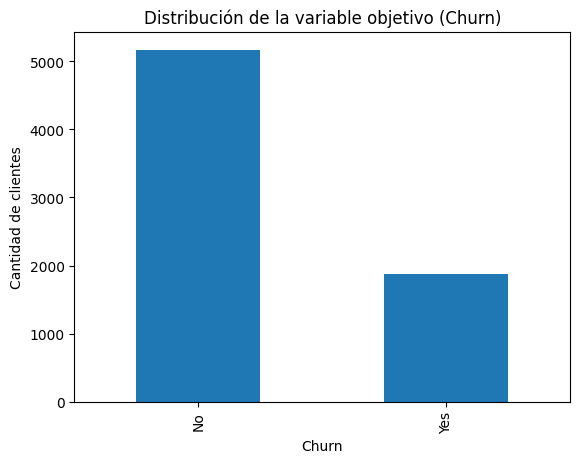

In [10]:
import matplotlib.pyplot as plt

df["Churn"].value_counts().plot(kind="bar")

plt.title("Distribución de la variable objetivo (Churn)")
plt.xlabel("Churn")
plt.ylabel("Cantidad de clientes")

plt.show()

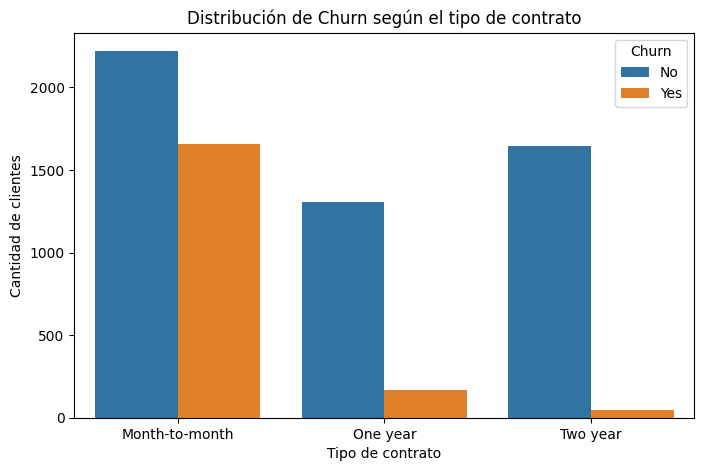

In [11]:
# Churn según tipo de contrato

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.countplot(data=df,
              x="Contract",
              hue="Churn")

plt.title("Distribución de Churn según el tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Cantidad de clientes")

plt.show()

## Distribución de Churn según el servicio de Internet

### Objetivo

Analizar si existe una relación entre el tipo de servicio de Internet contratado por los clientes y la probabilidad de abandono del servicio (Churn).

Este análisis permite identificar si determinados servicios presentan una mayor proporción de cancelaciones, lo que podría ayudar a la empresa a diseñar estrategias específicas de retención.


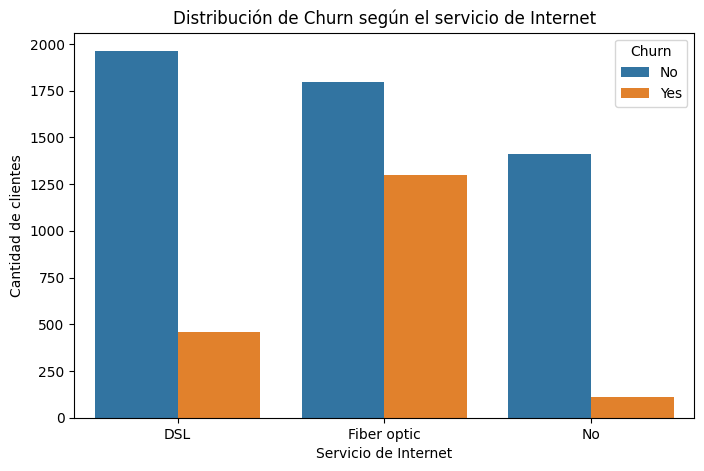

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Distribución de Churn según el servicio de Internet")
plt.xlabel("Servicio de Internet")
plt.ylabel("Cantidad de clientes")

plt.show()

### Interpretación

Se observa que los clientes con servicio de Internet por fibra óptica presentan una mayor cantidad de casos de abandono (Churn = Yes) en comparación con los clientes que utilizan DSL o que no poseen servicio de Internet.

Esto sugiere que el tipo de servicio contratado podría estar asociado con la probabilidad de cancelación y, por lo tanto, constituye una variable potencialmente relevante para el modelo de clasificación.

## Distribución de Churn según el método de pago

### Objetivo

Analizar si el método de pago utilizado por los clientes presenta alguna relación con la cancelación del servicio.

Este análisis permitirá identificar si determinados métodos de pago concentran una mayor cantidad de clientes que abandonan la empresa.

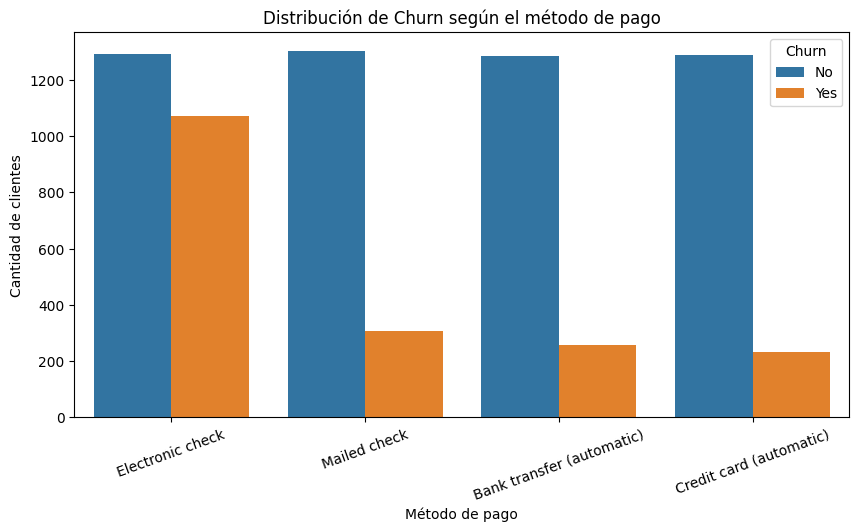

In [13]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.xticks(rotation=20)

plt.title("Distribución de Churn según el método de pago")
plt.xlabel("Método de pago")
plt.ylabel("Cantidad de clientes")

plt.show()

### Interpretación

Se observa que los clientes que utilizan **Electronic check** presentan una cantidad considerablemente mayor de casos de abandono (Churn = Yes) en comparación con los demás métodos de pago.

Por el contrario, los clientes que utilizan **transferencia bancaria automática**, **tarjeta de crédito automática** o **cheque enviado por correo** muestran una menor proporción de cancelaciones.

Este comportamiento sugiere que el método de pago podría estar asociado con la permanencia de los clientes y, por lo tanto, representa una variable potencialmente relevante para el modelo de clasificación.

##  Distribución de la antigüedad de los clientes

### Objetivo

Analizar la distribución de la antigüedad de los clientes (tenure) y evaluar si existen diferencias entre quienes permanecen en la empresa y quienes abandonan el servicio.

La antigüedad suele ser una de las variables más importantes para explicar el comportamiento de abandono de clientes.

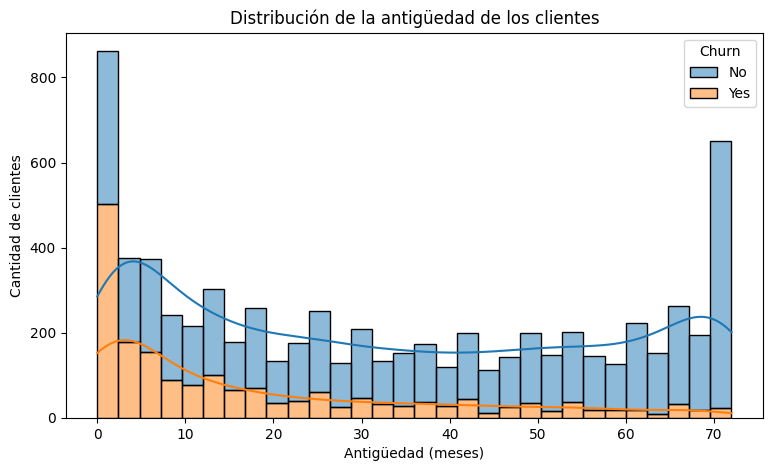

In [14]:
plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Distribución de la antigüedad de los clientes")
plt.xlabel("Antigüedad (meses)")
plt.ylabel("Cantidad de clientes")

plt.show()

### Interpretación

Se observa que la mayor cantidad de clientes que abandonan el servicio (Churn = Yes) se concentra en los primeros meses de antigüedad.

A medida que aumenta la permanencia de los clientes en la empresa, la cantidad de abandonos disminuye considerablemente, mientras que aumenta la proporción de clientes que permanecen activos.

Este comportamiento indica que la variable **tenure** es un fuerte indicador del abandono del servicio y, por lo tanto, se espera que tenga una elevada importancia durante el entrenamiento del modelo de Machine Learning.

##  Distribución del gasto mensual de los clientes

### Objetivo

Analizar cómo se distribuye el gasto mensual de los clientes (MonthlyCharges) y evaluar si existen diferencias entre quienes permanecen en la empresa y quienes cancelan el servicio.

El gasto mensual puede estar asociado al valor del cliente y a la probabilidad de abandono.

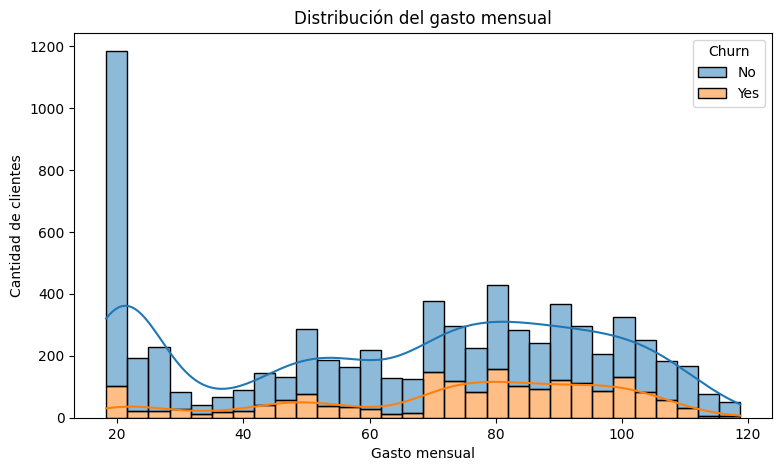

In [15]:
plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Distribución del gasto mensual")
plt.xlabel("Gasto mensual")
plt.ylabel("Cantidad de clientes")

plt.show()

### Interpretación

Se observa que los clientes con gastos mensuales más elevados presentan una mayor cantidad de casos de abandono (Churn = Yes) en comparación con aquellos que poseen gastos mensuales bajos.

En cambio, los clientes con menores cargos mensuales muestran una mayor proporción de permanencia en la empresa.

Este comportamiento sugiere que el gasto mensual (**MonthlyCharges**) podría estar asociado con la probabilidad de cancelación del servicio y, por lo tanto, representa una variable potencialmente relevante para el modelo de Machine Learning.

##  Comparación del gasto mensual según el estado de Churn

### Objetivo

Comparar la distribución del gasto mensual entre los clientes que permanecen en la empresa y aquellos que abandonan el servicio.

El boxplot permite analizar diferencias en la mediana, la dispersión de los datos y la presencia de posibles valores atípicos.

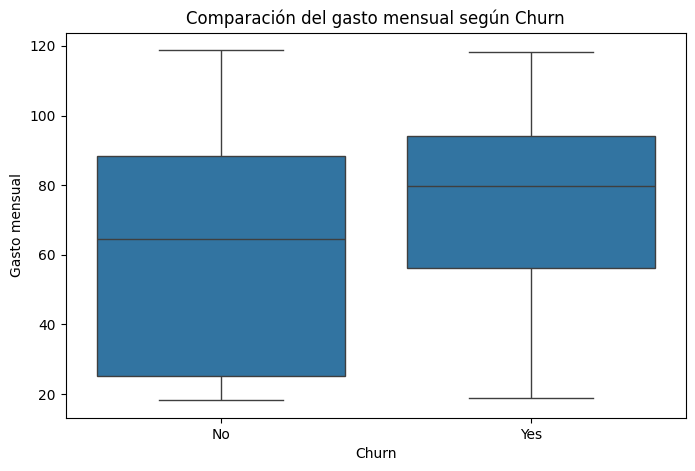

In [16]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Comparación del gasto mensual según Churn")
plt.xlabel("Churn")
plt.ylabel("Gasto mensual")

plt.show()

### Interpretación

El boxplot muestra que los clientes que abandonan el servicio (Churn = Yes) presentan una mediana de gasto mensual superior a la de aquellos que permanecen en la empresa.

Además, se observa que la distribución de los gastos mensuales de los clientes que cancelan el servicio se concentra en valores más elevados, mientras que los clientes que permanecen presentan una mayor dispersión e incluyen una mayor proporción de gastos bajos.

Estos resultados refuerzan la evidencia observada en el histograma anterior y sugieren que la variable **MonthlyCharges** podría desempeñar un papel importante en la predicción del abandono de clientes.

## Matriz de correlación

### Objetivo

Analizar la relación lineal entre las variables numéricas del conjunto de datos.

La matriz de correlación permite identificar asociaciones entre variables y detectar posibles problemas de multicolinealidad antes del entrenamiento de los modelos de Machine Learning.

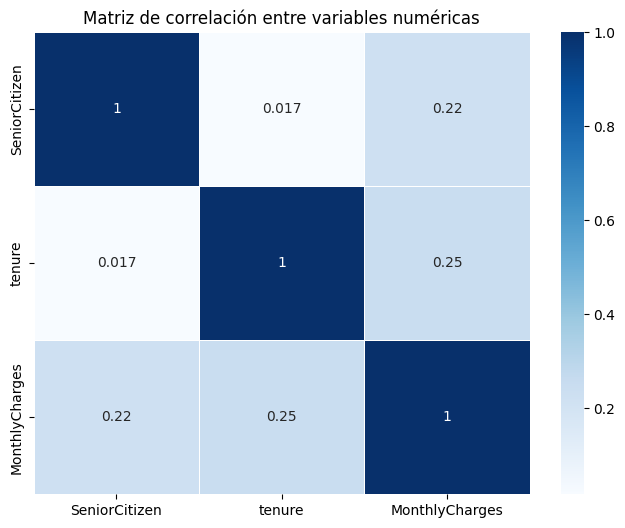

In [17]:
plt.figure(figsize=(8,6))

correlacion = df.select_dtypes(include=["int64", "float64"]).corr()

sns.heatmap(
    correlacion,
    annot=True,
    cmap="Blues",
    linewidths=0.5
)

plt.title("Matriz de correlación entre variables numéricas")

plt.show()

# ETL y Preprocesamiento de datos

## Objetivo

Preparar el conjunto de datos para el entrenamiento de modelos de Machine Learning.

En esta etapa se realizará la limpieza del dataset, la conversión de variables al tipo de dato adecuado, el tratamiento de valores faltantes y la preparación de las variables predictoras y la variable objetivo.

Un correcto preprocesamiento permite mejorar la calidad de los datos y evita errores durante el entrenamiento de los modelos.

## Conversión de la variable TotalCharges

### Objetivo

La variable **TotalCharges** debería ser numérica; sin embargo, se encuentra almacenada como texto debido a la presencia de algunos registros vacíos.

En esta etapa se convertirá la variable al tipo numérico y los valores inválidos pasarán a ser valores faltantes (NaN), que posteriormente serán tratados.

In [18]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"].dtype

dtype('float64')

## Verificación de valores faltantes

Después de convertir la variable **TotalCharges** a formato numérico, se verifica nuevamente la cantidad de valores faltantes presentes en el dataset.

In [19]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## Tratamiento de valores faltantes

La variable **TotalCharges** presenta únicamente 11 registros con valores faltantes, lo que representa una proporción muy pequeña respecto del total del dataset.

Debido a su escasa cantidad, se decidió eliminar estos registros para mantener la calidad de los datos sin afectar significativamente el tamaño de la muestra.

In [20]:
df = df.dropna()

df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## Dimensiones finales del dataset

Luego del tratamiento de los valores faltantes se verifica nuevamente el tamaño del conjunto de datos.

In [21]:
print(df.shape)

(7032, 21)


In [22]:
df = df.dropna()

df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [23]:
print(df.shape)

(7032, 21)


In [24]:
df = df.drop("customerID", axis=1)

In [25]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

In [26]:
numericas = X.select_dtypes(include=["int64","float64"]).columns

categoricas = X.select_dtypes(include="object").columns

In [27]:
print(numericas)

print(categoricas)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')
Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

In [30]:
preprocesador = ColumnTransformer(

    transformers=[

        ("num",
         StandardScaler(),
         numericas),

        ("cat",
         OneHotEncoder(handle_unknown="ignore"),
         categoricas)

    ]

)

# Modelado

## Modelo baseline: Regresión Logística

### Objetivo

Construir un primer modelo de clasificación utilizando Regresión Logística como baseline.

La Regresión Logística es un modelo simple, rápido e interpretable, por lo que resulta adecuada como punto de referencia para comparar posteriormente el desempeño de modelos más complejos.

El preprocesador y el modelo se integrarán dentro de un Pipeline, lo que garantiza que las transformaciones se ajusten únicamente con los datos de entrenamiento y ayuda a prevenir data leakage.

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [32]:
pipeline_logistica = Pipeline(
    steps=[
        ("preprocesador", preprocesador),
        ("modelo", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

## Entrenamiento del modelo baseline

El modelo se entrena utilizando únicamente el conjunto de entrenamiento.

El Pipeline aplica automáticamente el escalado de las variables numéricas, la codificación de las variables categóricas y, finalmente, el ajuste de la Regresión Logística.

In [33]:
pipeline_logistica.fit(X_train, y_train)

Pipeline(steps=[('preprocesador',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('modelo', LogisticRegression(max_iter=1000, random_state=42))])

## Predicciones sobre el conjunto de prueba

Una vez entrenado el modelo, se generan predicciones sobre el conjunto de prueba, que no fue utilizado durante el entrenamiento.

Esto permite evaluar la capacidad del modelo para generalizar frente a datos nuevos.

In [34]:
y_pred_logistica = pipeline_logistica.predict(X_test)

y_prob_logistica = pipeline_logistica.predict_proba(X_test)[:, 1]

## Evaluación del modelo baseline

El desempeño del modelo se evaluará mediante distintas métricas:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** proporción de clientes identificados como churn que realmente abandonaron.
- **Recall:** proporción de clientes que realmente abandonaron y fueron detectados por el modelo.
- **F1-score:** equilibrio entre Precision y Recall.
- **ROC-AUC:** capacidad del modelo para diferenciar entre clientes que abandonan y clientes que permanecen, independientemente de un umbral específico.

Dado que el objetivo de negocio consiste en identificar clientes en riesgo de abandono, el Recall de la clase positiva será una métrica especialmente relevante.

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

accuracy_logistica = accuracy_score(y_test, y_pred_logistica)

precision_logistica = precision_score(
    y_test,
    y_pred_logistica,
    pos_label="Yes"
)

recall_logistica = recall_score(
    y_test,
    y_pred_logistica,
    pos_label="Yes"
)

f1_logistica = f1_score(
    y_test,
    y_pred_logistica,
    pos_label="Yes"
)

roc_auc_logistica = roc_auc_score(
    y_test.map({"No": 0, "Yes": 1}),
    y_prob_logistica
)

print(f"Accuracy: {accuracy_logistica:.4f}")
print(f"Precision: {precision_logistica:.4f}")
print(f"Recall: {recall_logistica:.4f}")
print(f"F1-score: {f1_logistica:.4f}")
print(f"ROC-AUC: {roc_auc_logistica:.4f}")

Accuracy: 0.8038
Precision: 0.6485
Recall: 0.5722
F1-score: 0.6080
ROC-AUC: 0.8359


In [36]:
print("Reporte de clasificación:\n")
print(classification_report(y_test, y_pred_logistica))

Reporte de clasificación:

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



### Interpretación

El modelo de Regresión Logística obtuvo un **Accuracy del 80,38%**, lo que indica que clasifica correctamente aproximadamente ocho de cada diez clientes.

La métrica **ROC-AUC alcanzó un valor de 0,8359**, evidenciando una buena capacidad del modelo para diferenciar entre clientes que abandonan el servicio y aquellos que permanecen.

Sin embargo, el **Recall de la clase positiva fue del 57,22%**, lo que significa que todavía existe una proporción importante de clientes que abandonan el servicio y no son detectados por el modelo.

Estos resultados constituyen una línea base (baseline) adecuada para comparar posteriormente el desempeño de modelos más complejos, como Random Forest optimizado mediante GridSearchCV.

## Matriz de confusión

### Objetivo

La matriz de confusión permite analizar con mayor detalle los aciertos y errores del modelo.

En particular, permite identificar la cantidad de verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos, información fundamental para comprender el comportamiento del clasificador.

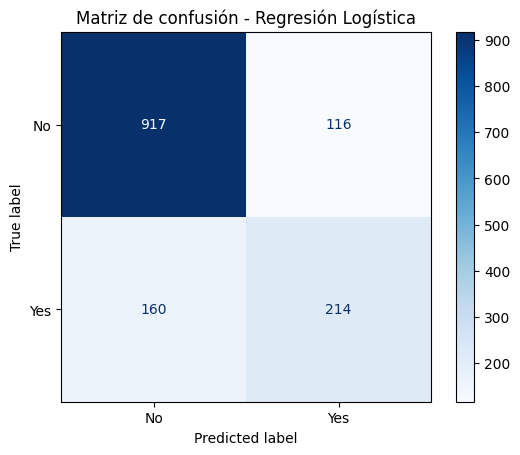

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistica,
    cmap="Blues"
)

plt.title("Matriz de confusión - Regresión Logística")

plt.show()

Interpretación
La matriz de confusión muestra que el modelo clasificó correctamente 917 clientes que permanecieron en la empresa (Verdaderos Negativos) y 214 clientes que efectivamente abandonaron el servicio (Verdaderos Positivos).

Asimismo, se observan 116 falsos positivos, es decir, clientes que fueron clasificados como posibles abandonos cuando en realidad permanecieron en la empresa.

Por otro lado, el modelo presentó 160 falsos negativos, correspondientes a clientes que realmente abandonaron el servicio pero que no fueron identificados por el modelo.

Estos resultados muestran que la Regresión Logística presenta un buen desempeño general, aunque todavía existe margen de mejora para incrementar la detección de clientes con riesgo de abandono.

## Curva ROC

### Objetivo

La curva ROC permite evaluar la capacidad del modelo para distinguir entre ambas clases utilizando distintos umbrales de decisión.

Cuanto más cercana se encuentre la curva al vértice superior izquierdo, mejor será el desempeño del modelo.

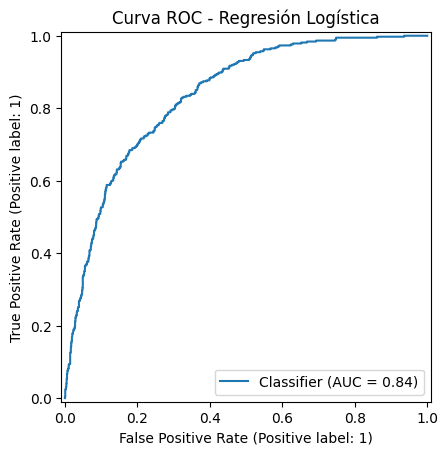

In [38]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test.map({"No":0,"Yes":1}),
    y_prob_logistica
)

plt.title("Curva ROC - Regresión Logística")

plt.show()

### Interpretación

La curva ROC se aproxima al vértice superior izquierdo del gráfico, indicando un buen desempeño del modelo para distinguir entre clientes que abandonan el servicio y aquellos que permanecen.

El área bajo la curva (**ROC-AUC = 0,84**) confirma que la Regresión Logística posee una buena capacidad de discriminación, superior a la obtenida por un clasificador aleatorio.

En conjunto, estos resultados muestran que el modelo baseline constituye una base sólida para compararlo posteriormente con modelos más complejos, como Random Forest.

# Modelo Random Forest

## Objetivo

Entrenar un modelo Random Forest para compararlo con la Regresión Logística.

Random Forest es un algoritmo basado en múltiples árboles de decisión que suele capturar relaciones no lineales entre las variables y ofrecer un mejor desempeño en problemas de clasificación.

Posteriormente, se compararán las métricas obtenidas por ambos modelos para seleccionar el más adecuado para el problema de negocio.

In [39]:
from sklearn.ensemble import RandomForestClassifier

In [40]:
pipeline_rf = Pipeline(

    steps=[

        ("preprocesador", preprocesador),

        ("modelo",

         RandomForestClassifier(

             random_state=42

         ))

    ]

)

In [41]:
pipeline_rf.fit(X_train, y_train)

Pipeline(steps=[('preprocesador',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                ('modelo', RandomForestClassifier(random_state=42))])

In [42]:
y_pred_rf = pipeline_rf.predict(X_test)

y_prob_rf = pipeline_rf.predict_proba(X_test)[:,1]

## Evaluación del modelo Random Forest

### Objetivo

Evaluar el desempeño del modelo Random Forest utilizando las mismas métricas empleadas en la Regresión Logística.

Esto permitirá realizar una comparación objetiva entre ambos modelos e identificar cuál ofrece un mejor desempeño para predecir el abandono de clientes.

In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    pos_label="Yes"
)

roc_auc_rf = roc_auc_score(
    y_test.map({"No":0,"Yes":1}),
    y_prob_rf
)

print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-score: {f1_rf:.4f}")
print(f"ROC-AUC: {roc_auc_rf:.4f}")

Accuracy: 0.7875
Precision: 0.6307
Recall: 0.4840
F1-score: 0.5477
ROC-AUC: 0.8137


In [44]:
print("Reporte de clasificación:\n")

print(classification_report(y_test, y_pred_rf))

Reporte de clasificación:

              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1033
         Yes       0.63      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407



### Interpretación

El modelo Random Forest obtuvo un **Accuracy del 78,75%**, clasificando correctamente aproximadamente ocho de cada diez clientes.

Sin embargo, al compararlo con la Regresión Logística, presentó un menor desempeño en las principales métricas de evaluación.

En particular, el **Recall descendió al 48,40%**, indicando que el modelo logró identificar una menor proporción de clientes que realmente abandonaron el servicio.

Asimismo, el valor de **ROC-AUC fue de 0,8137**, ligeramente inferior al obtenido por la Regresión Logística.

Estos resultados indican que, utilizando los parámetros por defecto, Random Forest no supera al modelo baseline y requiere un proceso de optimización de hiperparámetros para mejorar su desempeño.

## Matriz de confusión

La matriz de confusión permite visualizar la cantidad de aciertos y errores cometidos por el modelo Random Forest y compararlos posteriormente con los obtenidos mediante Regresión Logística.

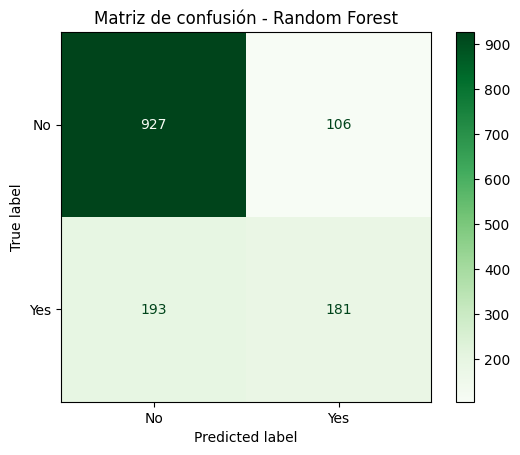

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    cmap="Greens"
)

plt.title("Matriz de confusión - Random Forest")

plt.show()

### Interpretación

La matriz de confusión muestra que el modelo clasificó correctamente **927 clientes que permanecieron en la empresa** y **181 clientes que efectivamente abandonaron el servicio**.

Además, se registraron **106 falsos positivos** y **193 falsos negativos**.

En comparación con la Regresión Logística, Random Forest redujo ligeramente los falsos positivos, pero aumentó la cantidad de falsos negativos, lo que explica la disminución del Recall observada anteriormente.

Dado que el objetivo del proyecto es detectar clientes con riesgo de abandono, este comportamiento representa una desventaja frente al modelo baseline.

## Curva ROC

La curva ROC permite analizar la capacidad discriminatoria del modelo Random Forest utilizando distintos umbrales de decisión.

Su comparación con la obtenida por la Regresión Logística permitirá determinar cuál de los dos modelos ofrece un mejor desempeño.

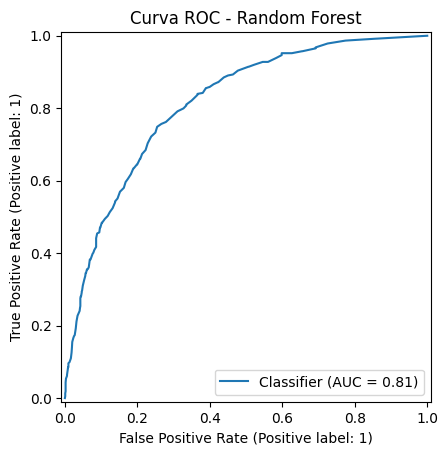

In [46]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test.map({"No":0,"Yes":1}),
    y_prob_rf
)

plt.title("Curva ROC - Random Forest")

plt.show()

### Interpretación

La curva ROC muestra un buen desempeño del modelo Random Forest para distinguir entre clientes que permanecen y clientes que abandonan el servicio.

El valor obtenido de **ROC-AUC = 0,8137** indica una adecuada capacidad discriminatoria, aunque ligeramente inferior a la alcanzada por la Regresión Logística.

Estos resultados sugieren que el modelo aún puede mejorar mediante la optimización de hiperparámetros utilizando GridSearchCV.

# Comparación entre modelos

Con el objetivo de seleccionar el modelo más adecuado para el problema de negocio, se comparan las principales métricas obtenidas por la Regresión Logística y Random Forest.

Esta comparación permitirá establecer una línea base antes de optimizar el modelo Random Forest mediante GridSearchCV.

In [47]:
import pandas as pd

comparacion = pd.DataFrame({

    "Métrica":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],

    "Regresión Logística":[
        accuracy_logistica,
        precision_logistica,
        recall_logistica,
        f1_logistica,
        roc_auc_logistica
    ],

    "Random Forest":[
        accuracy_rf,
        precision_rf,
        recall_rf,
        f1_rf,
        roc_auc_rf
    ]

})

comparacion

,Métrica,Regresión Logística,Random Forest
0,Accuracy,0.803838,0.787491
1,Precision,0.648485,0.630662
2,Recall,0.572193,0.483957
3,F1-score,0.607955,0.547655
4,ROC-AUC,0.835929,0.813661


### Interpretación

La comparación evidencia que la Regresión Logística obtuvo mejores resultados que Random Forest en todas las métricas evaluadas.

En particular, presentó mayor Accuracy, Recall, F1-score y ROC-AUC.

Esto indica que, utilizando la configuración por defecto, Random Forest no logró superar al modelo baseline.

Por este motivo, el siguiente paso consistirá en optimizar sus hiperparámetros mediante GridSearchCV para evaluar si es posible mejorar su desempeño.

# Optimización del modelo mediante GridSearchCV

## Objetivo

Optimizar el modelo Random Forest mediante una búsqueda sistemática de hiperparámetros utilizando GridSearchCV.

Esta técnica permite evaluar distintas combinaciones de parámetros mediante validación cruzada, seleccionando automáticamente aquella que ofrece el mejor desempeño según la métrica elegida.

En este proyecto se utilizará la métrica **ROC-AUC**, ya que resulta especialmente adecuada para problemas de clasificación binaria con cierto desbalance entre clases.

In [48]:
from sklearn.model_selection import GridSearchCV

In [49]:
param_grid = {

    "modelo__n_estimators": [100, 200],

    "modelo__max_depth": [None, 10, 20],

    "modelo__min_samples_split": [2, 5],

    "modelo__min_samples_leaf": [1, 2]

}

In [50]:
grid_search = GridSearchCV(

    estimator=pipeline_rf,

    param_grid=param_grid,

    cv=5,

    scoring="roc_auc",

    n_jobs=-1,

    verbose=1

)

In [51]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocesador',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity',...
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object'))])),
                                       ('modelo',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'modelo__max_depth': [None, 10, 20],
                         'modelo__min_samples_leaf': [1, 2],
                         'modelo__min_samples_split': [2, 5],
                         'modelo__n_estimators': [100, 200]},
             scoring='roc_auc', verbose=1)

In [52]:
print("Mejores parámetros encontrados:")
print(grid_search.best_params_)

Mejores parámetros encontrados:
{'modelo__max_depth': 10, 'modelo__min_samples_leaf': 2, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 200}


In [53]:
print("Mejor ROC-AUC obtenido en validación cruzada:")
print(grid_search.best_score_)

Mejor ROC-AUC obtenido en validación cruzada:
0.8442070825269056


In [54]:
mejor_modelo = grid_search.best_estimator_

In [55]:
y_pred_grid = mejor_modelo.predict(X_test)

y_prob_grid = mejor_modelo.predict_proba(X_test)[:, 1]

In [56]:
accuracy_grid = accuracy_score(y_test, y_pred_grid)

precision_grid = precision_score(
    y_test,
    y_pred_grid,
    pos_label="Yes"
)

recall_grid = recall_score(
    y_test,
    y_pred_grid,
    pos_label="Yes"
)

f1_grid = f1_score(
    y_test,
    y_pred_grid,
    pos_label="Yes"
)

roc_auc_grid = roc_auc_score(
    y_test.map({"No": 0, "Yes": 1}),
    y_prob_grid
)

print(f"Accuracy: {accuracy_grid:.4f}")
print(f"Precision: {precision_grid:.4f}")
print(f"Recall: {recall_grid:.4f}")
print(f"F1-score: {f1_grid:.4f}")
print(f"ROC-AUC: {roc_auc_grid:.4f}")

Accuracy: 0.7939
Precision: 0.6355
Recall: 0.5267
F1-score: 0.5760
ROC-AUC: 0.8330


### Interpretación

GridSearchCV seleccionó una configuración de Random Forest con 200 árboles, una profundidad máxima de 10 niveles y un mínimo de 2 observaciones por hoja.

El mejor ROC-AUC promedio obtenido durante la validación cruzada fue de aproximadamente **0,8442**, lo que evidencia una buena capacidad discriminatoria en los distintos subconjuntos de entrenamiento.

En el conjunto de prueba, el Random Forest optimizado obtuvo un **ROC-AUC de 0,8330**, un **Accuracy de 79,39%** y un **Recall de 52,67%** para la clase positiva.

La optimización permitió mejorar todas las métricas respecto del Random Forest con parámetros predeterminados. En particular, el Recall aumentó de 48,40% a 52,67%, permitiendo detectar una mayor proporción de clientes que realmente abandonaron el servicio.

A pesar de esta mejora, la Regresión Logística continúa presentando resultados ligeramente superiores, especialmente en Recall, F1-score y ROC-AUC.

# Comparación final de modelos

Se comparan los resultados de la Regresión Logística, el Random Forest con parámetros predeterminados y el Random Forest optimizado mediante GridSearchCV.

La comparación considera tanto el rendimiento general como la capacidad de detectar clientes que realmente abandonan el servicio.

In [57]:
comparacion_final = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Regresión Logística": [
        accuracy_logistica,
        precision_logistica,
        recall_logistica,
        f1_logistica,
        roc_auc_logistica
    ],
    "Random Forest": [
        accuracy_rf,
        precision_rf,
        recall_rf,
        f1_rf,
        roc_auc_rf
    ],
    "Random Forest optimizado": [
        accuracy_grid,
        precision_grid,
        recall_grid,
        f1_grid,
        roc_auc_grid
    ]
})

comparacion_final.round(4)

,Métrica,Regresión Logística,Random Forest,Random Forest optimizado
0,Accuracy,0.8038,0.7875,0.7939
1,Precision,0.6485,0.6307,0.6355
2,Recall,0.5722,0.4840,0.5267
3,F1-score,0.6080,0.5477,0.5760
4,ROC-AUC,0.8359,0.8137,0.8330


### Interpretación

La optimización mediante GridSearchCV mejoró el desempeño de Random Forest en todas las métricas evaluadas respecto de su configuración predeterminada.

No obstante, la Regresión Logística continúa obteniendo los mejores resultados generales. Presenta el mayor Accuracy, Precision, Recall, F1-score y ROC-AUC.

En particular, su Recall del **57,22%** indica que detecta una mayor proporción de clientes que realmente abandonan el servicio que las dos versiones de Random Forest.

Por lo tanto, considerando que el objetivo de negocio consiste en identificar clientes en riesgo para aplicar acciones de retención, la Regresión Logística sería el modelo seleccionado entre los tres evaluados.

Además de su mejor rendimiento, presenta ventajas de simplicidad, rapidez e interpretabilidad.

# Importancia de las variables

## Objetivo

Analizar cuáles fueron las variables que tuvieron mayor influencia en las decisiones del Random Forest optimizado.

Las importancias permiten obtener una aproximación de las características más utilizadas por el modelo para realizar sus predicciones.

Debe considerarse que las importancias basadas en reducción de impureza pueden favorecer variables continuas o variables categóricas que generan una mayor cantidad de columnas después del One-Hot Encoding.

In [58]:
# Obtener los nombres de las variables luego del preprocesamiento
nombres_variables = mejor_modelo.named_steps[
    "preprocesador"
].get_feature_names_out()

# Obtener las importancias del Random Forest optimizado
importancias = mejor_modelo.named_steps[
    "modelo"
].feature_importances_

# Crear una tabla ordenada
importancia_variables = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": importancias
}).sort_values(
    by="Importancia",
    ascending=False
)

importancia_variables.head(15)

,Variable,Importancia
1,num__tenure,0.154548
3,num__TotalCharges,0.119217
36,cat__Contract_Month-to-month,0.102063
2,num__MonthlyCharges,0.087847
18,cat__OnlineSecurity_No,0.053671
16,cat__InternetService_Fiber optic,0.049536
27,cat__TechSupport_No,0.044442
43,cat__PaymentMethod_Electronic check,0.038374
38,cat__Contract_Two year,0.032196
21,cat__OnlineBackup_No,0.020152


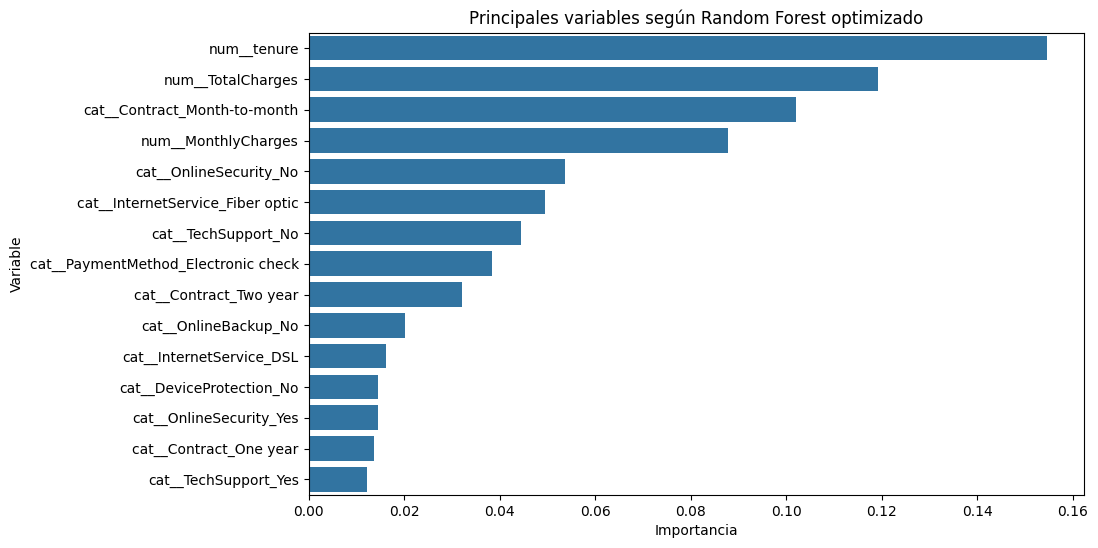

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancia_variables.head(15),
    x="Importancia",
    y="Variable"
)

plt.title("Principales variables según Random Forest optimizado")
plt.xlabel("Importancia")
plt.ylabel("Variable")

plt.show()

### Interpretación

El análisis de importancia de variables muestra que la **antigüedad del cliente (tenure)** fue la característica con mayor influencia en las decisiones del modelo Random Forest.

También resultaron especialmente relevantes el **gasto total acumulado (TotalCharges)**, el **tipo de contrato mensual (Month-to-month)** y el **gasto mensual (MonthlyCharges)**.

Entre las variables categóricas, la ausencia de **Online Security**, el servicio de **Fibra Óptica**, la ausencia de **Tech Support** y el método de pago mediante **Electronic Check** también presentaron una contribución importante para predecir el abandono.

Estos resultados son coherentes con el análisis exploratorio realizado anteriormente, donde se observó que los clientes con menor antigüedad, contratos mensuales y determinados tipos de servicio presentaban mayores tasas de cancelación.

En conjunto, el modelo confirma que estas variables representan los principales factores asociados al riesgo de abandono del servicio.

# Conclusiones

## Objetivo

Resumir los principales hallazgos obtenidos durante el análisis exploratorio, el entrenamiento de modelos y la evaluación final.

Asimismo, identificar cuál fue el modelo más adecuado para el problema de negocio y proponer posibles líneas de mejora para futuros trabajos.

### Conclusiones finales

Durante este proyecto se desarrolló un flujo completo de Ciencia de Datos para abordar un problema de clasificación binaria orientado a la predicción del abandono de clientes (Customer Churn).

En primer lugar, se realizó un análisis exploratorio del conjunto de datos, identificando la distribución de las variables, los valores faltantes, el desbalance de la variable objetivo y los principales patrones asociados al abandono.

Posteriormente, se aplicó un proceso de preprocesamiento utilizando un Pipeline con ColumnTransformer, incluyendo el escalado de variables numéricas y la codificación One-Hot de las variables categóricas.

Como modelo baseline se utilizó una Regresión Logística, obteniendo un desempeño sólido con un ROC-AUC de **0,8359** y un Recall del **57,22%**.

Luego se entrenó un modelo Random Forest y posteriormente se optimizó mediante GridSearchCV. La optimización permitió mejorar el rendimiento respecto del Random Forest inicial, aunque no logró superar a la Regresión Logística.

La comparación entre los tres modelos permitió concluir que la **Regresión Logística** fue el algoritmo con mejor desempeño general para este conjunto de datos, ofreciendo además una solución simple, rápida e interpretable.

Finalmente, el análisis de importancia de variables confirmó que la **antigüedad del cliente (tenure)**, el **tipo de contrato**, el **gasto mensual** y la contratación de determinados servicios representan los principales factores asociados al abandono del servicio.

Este tipo de modelos puede ser utilizado por empresas de telecomunicaciones para identificar clientes con riesgo de cancelación y diseñar campañas de retención más eficientes.

# Trabajo futuro

Como posibles mejoras del proyecto podrían implementarse las siguientes acciones:

- Incorporar nuevos algoritmos de Machine Learning como XGBoost, LightGBM o CatBoost.
- Probar técnicas de balanceo de clases como SMOTE.
- Ajustar el umbral de decisión para priorizar Recall o Precision según el objetivo de negocio.
- Incorporar nuevas variables relacionadas con el comportamiento de los clientes.
- Evaluar técnicas avanzadas de interpretación como SHAP Values.

## Cierre

El desarrollo de este proyecto permitió aplicar un flujo completo de Ciencia de Datos, integrando análisis exploratorio, preprocesamiento, construcción de pipelines, entrenamiento de modelos, optimización mediante GridSearchCV e interpretación de resultados.

Los conocimientos adquiridos durante este trabajo constituyen una base sólida para abordar futuros proyectos de Machine Learning en contextos reales.